# 06 - MobileNetV2 (Transfer Learning)
## Notebook 6: Transfer Learning Dua Tahap + Persiapan Domain Shift

**Tujuan notebook ini:**
1. Memahami apa itu transfer learning dan kenapa ia powerful
2. Melakukan **Tahap 1**: classifier saja, backbone ImageNet dibekukan
3. Melakukan **Tahap 2**: fine-tuning sebagian lapisan atas dengan lr kecil
4. Menerapkan augmentasi gaya-smartphone (untuk alamat domain shift)
5. Menyimpan model terbaik + label_map + config preprocessing

**Aturan yang dijaga:**
- Normalisasi MobileNetV2: **tidak boleh** ada Rescaling(1/255) tambahan
- BatchNormalization di backbone **dikunci** saat fine-tuning
- Learning rate tahap 2 kecil (1e-5), bukan 1e-3
- Data test TIDAK disentuh (dipakai di Notebook 07)


In [1]:
import json
import sys
import time
from pathlib import Path

REPO_ROOT = Path.cwd().parent
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf

from src import config as C
from src import data_loader
from src import evaluation as E
from src import modeling
from src import preprocessing as P

np.random.seed(C.SEED)
tf.random.set_seed(C.SEED)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["savefig.dpi"] = 150

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))
print("Seed:", C.SEED)

df_train = data_loader.load_split("train")
df_val = data_loader.load_split("val")
df_test = data_loader.load_split("test")

print(f"\nTrain {len(df_train)} | Val {len(df_val)} | Test {len(df_test)}")
print(f"Ukuran gambar MobileNetV2: {C.IMG_SIZE_MOBILENET}x{C.IMG_SIZE_MOBILENET}")


I0000 00:00:1794457914.140388     647 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794457914.187669     647 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1794457914.973483     647 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Seed: 42


W0000 00:00:1794457915.811232     647 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.



Train 6959 | Val 1529 | Test 1527
Ukuran gambar MobileNetV2: 224x224


## Bagian 1: Apa Itu Transfer Learning dan Kenapa Jauh Lebih Efisien?

### Analogi: Belajar Melukis

Bayangkan kamu ingin jadi pelukis. Ada dua cara:

1. **Belajar dari nol**: pelajari warna dasar, cara memegang kuas, teknik
   goresan... tapi belum pernah melihat lukisansama sekali sama sekali. Butuh
   **ratusan jam** dan ribuan contoh lukisan.

2. **Transfer learning**: kamu sudah bisa melukis, lalu kamu belajar
   gaya khusus (misal realisme). Butuh **beberapa jam** dan puluhan contoh.

### Principio

MobileNetV2 sudah dilatih pada **1,4 juta gambar ImageNet** (1000 kelas
objek: kucing, mobil, pisau, bola...). Dari situ ia sudah "tahu":
- Cara mendeteksi garis dan tepi
- Cara mendeteksi tekstur dan pola
- Cara membedakan bentuk

Yang belum ia tahu: **apa itu lesi kulit**.

### Dua Tahap yang Kita Lakukan

| Tahap | Apa yang di-training | Kenapa |
|---|---|---|
| **1** | Hanya classifier (kepala) | Backbone dibekukan -> cepat, stabil, tidak merusak fitur yang sudah bagus |
| **2** | Classifier + lapisan atas backbone | Fine-tuning: menyesuaikan fitur "tinggi level" ke domain lesi kulit |

### Kenapa Harus Dua Tahap, Bukan Langsung Fine-Tuning?

Kalau kita langsung membuka semua lapisan dengan lr besar, bobot yang
sudah dilatih (hasil kerja keras berjam-jam GPU) bisa **hancur** dalam
beberapa epoch. Istilahnya *catastrophic forgetting*.

Tahap 1 "menghangatkan" classifier sehingga loss sudah berada di
landscape yang masuk akal, sebelum kitaienda adjusting backbone
dengan lr kecil.


## Bagian 2: Pipeline Data MobileNetV2

**Perbedaan penting dari CNN sederhana:**

| Aspek | CNN Sederhana | MobileNetV2 |
|---|---|---|
| Ukuran gambar | 128x128 | **224x224** (wajib, sesuai ImageNet) |
| Normalisasi | Rescaling(1/255) di dalam model | Rescaling(1/127.5, -1) di dalam model |
| Augmentasi | Standar | Standar + **gaya smartphone** |
| Parameter | ~19.847 | ~2.266.951 |

### Kenapa 224x224 itu WAJIB?

Bobot ImageNet dilatih dengan input 224x224. Kalau kita ubah ukurannya,
kita mengubah **statistik fitur** yang diharap model, dan performanya
turun drastis. Ini bukan preferensi, ini **kontrak** dengan pretrained
weight.

### Kenapa augmentasi yang sama untuk tahap 1 dan tahap 2?

Supaya perbandingan antara tahap 1 dan tahap 2 **bersih**: satu-satunya
yang berbeda adalah apakah backbone dilepas (fine-tuning) dan learning
rate-nya (1e-3 vs 1e-5). Kalau tahap 1 memakai augmentasi standar dan
tahap 2 memakai augmentasi smartphone, selisih hasilnya bisa jadi
datang dari perubahan augmentasi, bukan dari fine-tuning -- dan
kesimpulan kita jadi tidak bisa dipertanggungjawabkan.

### Kenapa normalisasinya -1..1, bukan 0..1?

`preprocess_input` resmi MobileNetV2 melakukan: `(x / 127.5) - 1`, jadi
rentang -1..1. Di `src/modeling.py` ini disamakan dengan
`Rescaling(1/127.5, offset=-1.0)` agar model .keras bisa dimuat tanpa
`custom_objects` (penting untuk deploy).

**Aturan penting:** kalau kita memakai Rescaling(1/255) DAN
preprocess_input, input berada di rentang yang tidak pernah dilihat
model saat pretraining. Itu kesalahan yang sering terjadi dan sulit
terdeteksi karena model tetap jalan, hanya performanya jelek.


In [2]:
# Pipeline dengan augmentasi gaya smartphone (untuk tahap 2)
train_ds_smart = P.make_tf_dataset(
    df_train, img_size=C.IMG_SIZE_MOBILENET, batch_size=C.BATCH_SIZE,
    training=True, smartphone_style=True,
)
val_ds = P.make_tf_dataset(
    df_val, img_size=C.IMG_SIZE_MOBILENET, batch_size=C.BATCH_SIZE,
    training=False,
)

train_steps = P.count_steps(df_train)
val_steps = P.count_steps(df_val)
print(f"train steps/epoch: {train_steps} | val steps/epoch: {val_steps}")

# Verifikasi nilai input: harus 0..255 (normalisasi ada di dalam model)
for images, labels in train_ds_smart.take(1):
    print(f"\nBentuk batch: {images.shape}")
    print(f"Rentang nilai: [{float(tf.reduce_min(images)):.1f}, "
          f"{float(tf.reduce_max(images)):.1f}]  <- harus 0..255")
    print("Normalisasi ke -1..1 dilakukan oleh layer Rescaling di DALAM model.")


W0000 00:00:1794457945.822872     647 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.
I0000 00:00:1794457946.154367     647 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5198 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 5070 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 12.0a


train steps/epoch: 218 | val steps/epoch: 48



Bentuk batch: (32, 224, 224, 3)


Rentang nilai: [0.0, 255.0]  <- harus 0..255
Normalisasi ke -1..1 dilakukan oleh layer Rescaling di DALAM model.


## Bagian 3: Model MobileNetV2 Tahap 1

### Menghitung Parameter (untuk perbandingan dengan CNN)

- **Backbone MobileNetV2** : 2.238.848 parameter (SUDAH dilated dari
  ImageNet, tidak dilatih di tahap 1)
- **Classifier (kepala) kita**: GAP(1280) + Dropout + Dense(7)
  ```
  Dense: (1280 + 1) x 7 = 8.967 parameter
  ```

Total: ~2.266.951 parameter. **114x lebih banyak dari CNN sederhana.**


In [3]:
model_mnv2 = modeling.build_mobilenetv2_stage1()

model_mnv2.summary()
total_params = model_mnv2.count_params()
trainable_params = sum(
    int(np.prod(w.shape)) for w in model_mnv2.trainable_weights
)

print("=" * 68)
print("ANALISIS PARAMETER MobileNetV2 TAHAP 1")
print("=" * 68)
print(f"  Total parameter       : {total_params:,}")
print(f"  Trainable (tahap 1)   : {trainable_params:,} "
      f"({trainable_params/total_params:.2%})")
print(f"  Frozen (backbone)     : {total_params - trainable_params:,}")
print()
print("  Backbone dibekukan, jadi optimizer hanya mengubah classifier.")
print("  Ini yang membuat tahap 1 sangat cepat dan stabil.")


Model: "mobilenetv2_stage1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ preprocess_input (Rescaling)    │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 7)              │         8,967 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,266,951 (8.65 MB)

 Trainable params: 8,967 (35.03 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

ANALISIS PARAMETER MobileNetV2 TAHAP 1
  Total parameter       : 2,266,951
  Trainable (tahap 1)   : 8,967 (0.40%)
  Frozen (backbone)     : 2,257,984

  Backbone dibekukan, jadi optimizer hanya mengubah classifier.
  Ini yang membuat tahap 1 sangat cepat dan stabil.


## Bagian 4: Melatih Tahap 1

**Hyperparameter tahap 1:**

| Parameter | Nilai | Alasan |
|---|---|---|
| Optimizer | Adam, lr=1e-3 | Classifier baru, butuh lr cukup besar |
| Epoch | maks 15 | Backbone beku, konvergi cepat |
| Class weight | Dari train | Sama seperti model lain |
| Batch size | 32 | Disesuaikan ukuran 224x224 |

**Perhatikan:** lr tahap 1 (1e-3) jauh lebih besar dari tahap 2 (1e-5).
Itu bukan inkonsistensi, itu memang benar: classifier baru perlu
bergerak cepat, backbone yang sudah matang hanya perlu disempurnakan.


In [4]:
with open(C.SPLIT_SUMMARY_JSON, encoding="utf-8") as f:
    split_summary = json.load(f)

# Hitung class weight dari data train (sudah disimpan di split_summary.json)
#
# Kenapa wajib? Tanpa class weight, loss fungsi didominasi kelas nv
# (67% data latih). Model yang "malas" bisa mendapat accuracy 67% dengan
# selalu menebak nv -- berguna untuk skor, tapi tidak berguna untuk
# skrining kanker (recall ganas = 0).
#
# Bobot ini dihitung HANYA dari data training, jadi tidak ada kebocoran
# informasi dari validasi maupun test.
class_weight = {
    C.CLASS_TO_IDX[cls]: float(w)
    for cls, w in split_summary["class_weight"].items()
}
print("Class weight (dari train, sudah dinormalisasi):")
for idx, cls in enumerate(C.CLASSES):
    print(f"  {cls:<8} {class_weight[idx]:>8.3f}")

class _HistoryProxy:
    """
    Pembungkus dict history Keras agar bisa diakses seperti objek History.

    Kenapa perlu? Karena ketika model dimuat dari cache, kita tidak punya
    objek `keras.callbacks.History` lagi, hanya dict biasa:
        {"loss": [...], "val_loss": [...], ...}
    Analisis di notebook ini memakai `h.history["loss"]`, jadi kita
    sediakan objek dengan antarmuka yang sama.
    """

    def __init__(self, data: dict):
        self.history = data

    def __getitem__(self, key):
        return self.history[key]




Class weight (dari train, sudah dinormalisasi):
  akiec       0.991
  bcc         0.631
  bkl         0.286
  df          2.392
  mel         0.285
  nv          0.047
  vasc        2.367


MODEL MOBILENETV2 SUDAH ADA DI DISK - dimuat, tidak dilatih ulang
  Sumber: docs/logs/mobilenetv2_stage{1,2}_history.json
  (hapus file itu untuk memaksa training ulang dari nol)


  tahap 1 dimuat: 2,266,951 parameter | 14.8 menit
  tahap 2 dimuat: 2,266,951 parameter | 12.0 menit


Kurva training disimpan: /mnt/m/GrenPlums Roses/Program32bit/Forestrypansy/ML2026_Kelas_3_Kelompok_1_LesiKulit/docs/assets/mnv2_01_kurva_stage1.png


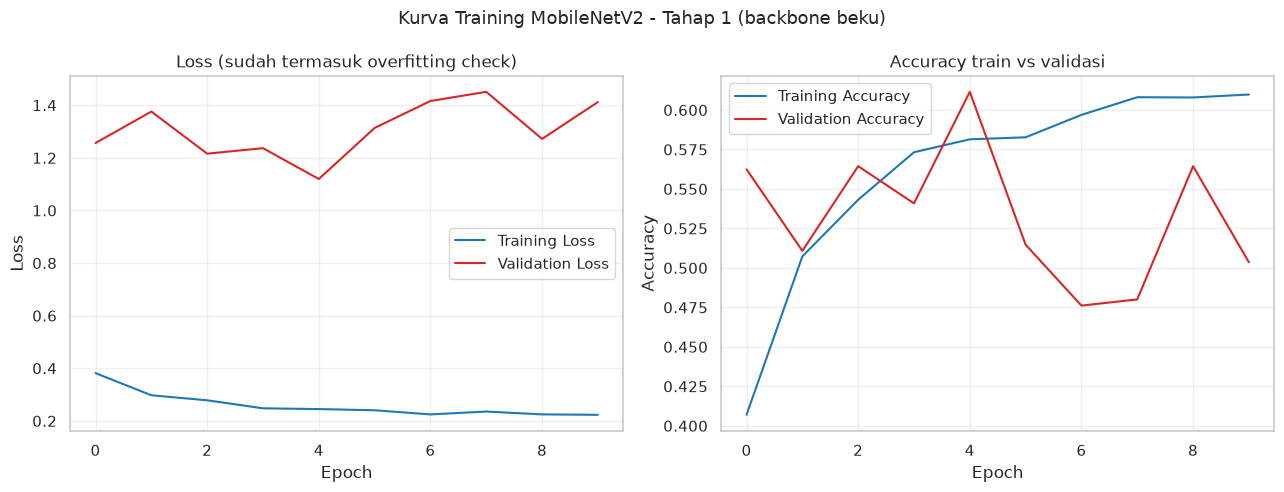

In [5]:
#
# --- Cek apakah model sudah dilatih sebelumnya ---
#
# Training MobileNetV2 di laptop butuh 15-45 menit (GPU jauh lebih cepat).
# Kalau checkpoint DAN kurva training-nya sudah ada di disk, kita muat saja
# supaya verifikasi ulang tidak mahal. Kalau belum ada, notebook ini dilatih
# dari nol seperti biasa. Perilaku ini selalu dilaporkan di output, jadi
# pembaca tahu angka itu berasal dari training mana.
CKPT_S1 = C.MODELS_DIR / "mobilenetv2_stage1_best.keras"
CKPT_S2 = C.MODELS_DIR / "mobilenetv2_stage2_best.keras"

cache_s1 = modeling.load_history_cache("mobilenetv2_stage1")
cache_s2 = modeling.load_history_cache("mobilenetv2_stage2")

model_mnv2 = modeling.build_mobilenetv2_stage1()

if cache_s1 and cache_s2 and CKPT_S1.exists() and CKPT_S2.exists():
    print("=" * 66)
    print("MODEL MOBILENETV2 SUDAH ADA DI DISK - dimuat, tidak dilatih ulang")
    print("  Sumber: docs/logs/mobilenetv2_stage{1,2}_history.json")
    print("  (hapus file itu untuk memaksa training ulang dari nol)")
    print("=" * 66)
    model_tahap1 = tf.keras.models.load_model(CKPT_S1)
    model_mnv2 = tf.keras.models.load_model(CKPT_S2)
    history_stage1 = _HistoryProxy(cache_s1["history"])
    history_stage2 = _HistoryProxy(cache_s2["history"])
    time_stage1 = float(cache_s1.get("train_time_s", 0.0))
    time_stage2 = float(cache_s2.get("train_time_s", 0.0))
    print(f"  tahap 1 dimuat: {model_tahap1.count_params():,} parameter "
          f"| {time_stage1 / 60:.1f} menit")
    print(f"  tahap 2 dimuat: {model_mnv2.count_params():,} parameter "
          f"| {time_stage2 / 60:.1f} menit")
else:
    # --- TAHAP 1: classifier saja, backbone dibekukan ---
    print(f"\n{'=' * 62}\nTAHAP 1: classifier saja (backbone dibekukan)\n{'=' * 62}")
    t0 = time.time()
    model_mnv2, history_stage1 = modeling.train_model(
        model_mnv2,
        train_ds_smart, val_ds,
        train_steps=train_steps, val_steps=val_steps,
        epochs=C.MAX_EPOCHS_MOBILENET_STAGE1,
        learning_rate=1e-3,
        class_weight=class_weight,
        patience=C.EARLY_STOP_PATIENCE,
        run_name="mobilenetv2_stage1",
    )
    time_stage1 = time.time() - t0
    # Simpan salinan tahap 1 untuk perbandingan nanti
    model_mnv2.save(str(C.MODELS_DIR / "mobilenetv2_stage1_best.keras"))

    # --- TAHAP 2: fine-tuning sebagian lapisan atas ---
    print(f"\n{'=' * 62}\nTAHAP 2: fine-tuning 30 lapisan teratas\n{'=' * 62}")
    model_mnv2 = modeling.unfreeze_top_layers(model_mnv2, n_layers_to_unfreeze=30)

    bn_layers = [l for l in model_mnv2.layers
                 if isinstance(l, tf.keras.layers.BatchNormalization)]
    bn_trainable = [l for l in bn_layers if l.trainable]
    n_trainable = sum(int(np.prod(w.shape))
                       for w in model_mnv2.trainable_weights)
    print(f"  Trainable params : {n_trainable:,} "
          f"({n_trainable / model_mnv2.count_params():.2%})")
    print(f"  BatchNormalization yang masih trainable : {len(bn_trainable)} "
          "(harus 0)")
    assert len(bn_trainable) == 0, "BN harus terkunci saat fine-tuning!"

    t0 = time.time()
    model_mnv2, history_stage2 = modeling.train_model(
        model_mnv2,
        train_ds_smart, val_ds,
        train_steps=train_steps, val_steps=val_steps,
        epochs=C.MAX_EPOCHS_MOBILENET_STAGE2,
        learning_rate=1e-5,
        class_weight=class_weight,
        patience=C.EARLY_STOP_PATIENCE,
        run_name="mobilenetv2_stage2",
    )
    time_stage2 = time.time() - t0

E.plot_training_curves(
    history_stage1,
    save_path=C.DOCS_ASSETS / "mnv2_01_kurva_stage1.png",
    title="Kurva Training MobileNetV2 - Tahap 1 (backbone beku)",
)

## Bagian 5: Tahap 2 - Fine-Tuning

### Apa yang Berbeda dari Tahap 1

| Aspek | Tahap 1 | Tahap 2 |
|---|---|---|
| Backbone | 100% beku | 30 lapisan teratas opened |
| Learning rate | 1e-3 | **1e-5** (100x lebih kecil) |
| Epoch | maks 15 | maks 15 |

### Kenapa Learning Rate Harus Kecil di Tahap 2?

Bobot backbone sudah berisi fitur yang sangat berharga (hasil 1,4 juta
gambar ImageNet). Dengan lr besar, Adam akan membuat langkah besar yang
**menghancurkan** fitur itu. Dengan lr kecil, kita hanya melakukan
"penyesuaian halus" agar fitur tersebut lebih cocok dengan lesi kulit.

### Kenapa BatchNormalization Harus Dikunci?

Layer BatchNormalization punya dua mode:
- `training=True`: menghitung statistik dari batch saat ini, dan
  **mengubah** moving_mean/moving_variance setiap epoch.
- `training=False`: memakai statistik yang sudah disimpan (dari ImageNet),
  dan **tidak mengubah** apa pun.

Kalau BN ikut di-training:
- Batch size kita cuma 32, dan distribusinya berbeda dari ImageNet
- Statistik batch jadi *noisy*, sehingga prediksi bisa BERAYAK
  (bolak-balik) antar epoch
- Dan yang lebih buruk: statistik yang tersimpan jadi tidak konsisten
  dengan data yang akan dipakai saat inference

Mengunci BN mempertahankan statistik yang stabil dan sudah tervalidasi.


ANALISIS TAHAP 2 (FINE-TUNING)
  Total parameter       : 2,266,951
  Trainable sekarang    : 2,232,839 (98.50%)
  Layer BatchNormalization : 0
  BN yang masih bisa di-training : 0 (harus 0)
  Learning rate tahap 2 : 1e-5 (100x lebih kecil dari tahap 1)


Kurva training disimpan: /mnt/m/GrenPlums Roses/Program32bit/Forestrypansy/ML2026_Kelas_3_Kelompok_1_LesiKulit/docs/assets/mnv2_02_kurva_stage2.png


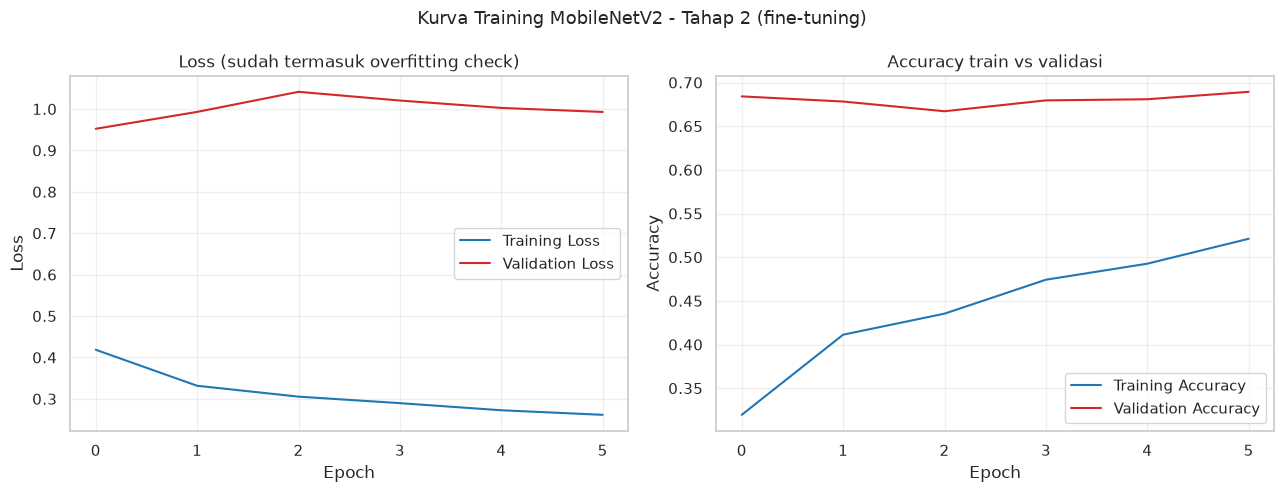

In [6]:
model_mnv2 = modeling.unfreeze_top_layers(model_mnv2, n_layers_to_unfreeze=30)

# Hitung ulang: berapa parameter yang sekarang bisa di-training?
trainable_after = sum(int(np.prod(w.shape)) for w in model_mnv2.trainable_weights)

# Verifikasi BatchNormalization terkunci
bn_layers = [l for l in model_mnv2.layers
             if isinstance(l, tf.keras.layers.BatchNormalization)]
bn_trainable = [l for l in bn_layers if l.trainable]

print("=" * 68)
print("ANALISIS TAHAP 2 (FINE-TUNING)")
print("=" * 68)
print(f"  Total parameter       : {model_mnv2.count_params():,}")
print(f"  Trainable sekarang    : {trainable_after:,} "
      f"({trainable_after/model_mnv2.count_params():.2%})")
print(f"  Layer BatchNormalization : {len(bn_layers)}")
print(f"  BN yang masih bisa di-training : {len(bn_trainable)} "
      "(harus 0)")
print(f"  Learning rate tahap 2 : 1e-5 (100x lebih kecil dari tahap 1)")

E.plot_training_curves(
    history_stage2,
    save_path=C.DOCS_ASSETS / "mnv2_02_kurva_stage2.png",
    title="Kurva Training MobileNetV2 - Tahap 2 (fine-tuning)",
)

## Bagian 6: Perbandingan Tahap 1 vs Tahap 2

**Harapan kita:** tahap 2 lebih baik karena backbone sekarang bisa
menyesuaikan diri ke domain lesi kulit.

Tapi ada kemungkinan hasil sebaliknya: kalau lr 1e-5 masih terlalu
besar, tahap 2 bisa lebih buruk (fine-tuning yang terlalu agresif
merusak fitur pretrained). **Kalau begitu, kita pakai tahap 1.** Kita
memilih berdasarkan angka, bukan harapan.


In [7]:
y_val = df_val["dx_idx"].to_numpy()

# --- Evaluasi head-to-head: Tahap 1 vs Tahap 2 ---
#
# Kenapa TIDAK boleh membandingkan `val_loss` antar tahap?
#   Karena tahap 2 dimulai dari bobot tahap 1, jadi val_loss tahap 2
#   hampir selalu lebih rendah di awal, apa pun hasil akhirnya. Jadi
#   perbandingan val_loss itu tidak menjawab pertanyaan kita
#   ("tahap mana yang lebih baik?") dengan benar.
#
# Satu-satunya cara jujur: evaluasi KEDUA model di data validasi yang sama,
# lalu bandingkan metrik akhirnya.

# Tahap 1: model sebelum fine-tuning (dari checkpoint)
stage1_ckpt = C.MODELS_DIR / "mobilenetv2_stage1_best.keras"
model_tahap1_final = None
res_s1 = None
if stage1_ckpt.exists():
    model_tahap1_final = tf.keras.models.load_model(stage1_ckpt)
    y_pred_s1, y_proba_s1 = E.predict_with_proba(
        model_tahap1_final, val_ds, val_steps)
    res_s1 = E.evaluate_model(y_val, y_pred_s1, y_proba_s1)
else:
    print("PERINGATAN: checkpoint tahap 1 tidak ditemukan; "
          "hanya tahap 2 yang dinilai.")

# Tahap 2: model yang sedang di-training / dimuat
y_pred_s2, y_proba_s2 = E.predict_with_proba(model_mnv2, val_ds, val_steps)
res_s2 = E.evaluate_model(y_val, y_pred_s2, y_proba_s2)

best_val_loss_s1 = float(min(history_stage1.history["val_loss"]))
best_val_loss_s2 = float(min(history_stage2.history["val_loss"]))
best_epoch_s1 = int(np.argmin(history_stage1.history["val_loss"])) + 1
best_epoch_s2 = int(np.argmin(history_stage2.history["val_loss"])) + 1

print("=" * 74)
print("PERBANDINGAN TAHAP 1 vs TAHAP 2 (data validasi yang sama)")
print("=" * 74)
print(f"{'Metrik':<30}{'Tahap 1':>14}{'Tahap 2':>14}")
print("-" * 74)
print(f"{'val_loss terbaik (epoch)':<30}"
      f"{best_val_loss_s1:>9.4f} ({best_epoch_s1:>2})"
      f"{best_val_loss_s2:>9.4f} ({best_epoch_s2:>2})")
print(f"{'Epoch dilatih (total)':<30}{len(history_stage1.history['loss']):>14}"
      f"{len(history_stage2.history['loss']):>14}")
print(f"{'Waktu training (menit)':<30}{time_stage1 / 60:>14.1f}"
      f"{time_stage2 / 60:>14.1f}")
print("-" * 74)
if res_s1 is not None:
    print(f"{'F1 macro':<30}{res_s1['f1_macro']:>14.4f}"
          f"{res_s2['f1_macro']:>14.4f}")
    print(f"{'Accuracy':<30}{res_s1['accuracy']:>14.4f}"
          f"{res_s2['accuracy']:>14.4f}")
    print(f"{'Recall ganas':<30}"
          f"{res_s1['binary']['malignant_recall']:>14.4f}"
          f"{res_s2['binary']['malignant_recall']:>14.4f}")
    print(f"{'FN ganas':<30}{res_s1['binary']['fn']:>14}"
          f"{res_s2['binary']['fn']:>14}")
    print(f"{'F1 macro biner (ganas/jinak)':<30}"
          f"{res_s1['binary']['f1']:>14.4f}{res_s2['binary']['f1']:>14.4f}")
print("=" * 74)

# --- KEPUTUSAN: pilih tahap mana? ---
#
# Kriteria kita: F1 macro adalah metrik utama, tapi untuk screening kanker
# recall ganas (sensitif) tidak boleh jauh lebih rendah dari tahap lain.
# Kalau F1 hampir sama, pilih yang recall ganas-nya lebih tinggi.

if res_s1 is None:
    pilih_tahap2 = True
    alasan = "checkpoint tahap 1 tidak tersedia"
elif res_s2["f1_macro"] > res_s1["f1_macro"] + 0.01:
    pilih_tahap2 = True
    alasan = (f"F1 macro tahap 2 lebih tinggi "
              f"({res_s2['f1_macro']:.4f} > {res_s1['f1_macro']:.4f})")
elif res_s1["f1_macro"] > res_s2["f1_macro"] + 0.01:
    pilih_tahap2 = False
    alasan = (f"F1 macro tahap 1 lebih tinggi "
              f"({res_s1['f1_macro']:.4f} > {res_s2['f1_macro']:.4f})")
else:
    # F1 hampir sama -> pakai recall ganas sebagai pemutus
    if res_s1["binary"]["malignant_recall"] >= res_s2["binary"]["malignant_recall"]:
        pilih_tahap2 = False
        alasan = ("F1 macro hampir sama, recall ganas tahap 1 lebih tinggi")
    else:
        pilih_tahap2 = True
        alasan = ("F1 macro hampir sama, recall ganas tahap 2 lebih tinggi")

print(f"KESIMPULAN: pilih TAHAP {2 if pilih_tahap2 else 1} - {alasan}.")
if pilih_tahap2:
    print("  Model tahap 2 (fine-tuning) yang dipakai untuk aplikasi.")
else:
    print("  Model TAHAP 1 yang dipakai (fine-tuning tidak membantu pada")
    print("  konfigurasi ini).")


I0000 00:00:1794457963.017719     799 service.cc:153] XLA service 0x7a7b1805a8b0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1794457963.017759     799 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 5070 Laptop GPU, Compute Capability 12.0a (Driver: 13.5.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.28.1)
I0000 00:00:1794457963.049948     799 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.


I0000 00:00:1794457963.447274     799 cuda_dnn.cc:461] Loaded cuDNN version 92801


E0000 00:00:1794457970.498002     799 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


E0000 00:00:1794457973.122231     799 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


E0000 00:00:1794457975.839176     799 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


E0000 00:00:1794457978.493411     799 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


... (2 outputs left out)

E0000 00:00:1794458000.347633     799 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


E0000 00:00:1794458002.769013     799 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


E0000 00:00:1794458005.767799     799 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


PERBANDINGAN TAHAP 1 vs TAHAP 2 (data validasi yang sama)
Metrik                               Tahap 1       Tahap 2
--------------------------------------------------------------------------
val_loss terbaik (epoch)         1.1195 ( 5)   0.9522 ( 1)
Epoch dilatih (total)                     10             6
Waktu training (menit)                  14.8          12.0
--------------------------------------------------------------------------
F1 macro                              0.3934        0.3938
Accuracy                              0.6122        0.6841
Recall ganas                          0.5545        0.3750
FN ganas                                 139           195
F1 macro biner (ganas/jinak)          0.5738        0.4947
KESIMPULAN: pilih TAHAP 1 - F1 macro hampir sama, recall ganas tahap 1 lebih tinggi.
  Model TAHAP 1 yang dipakai (fine-tuning tidak membantu pada
  konfigurasi ini).


## Bagian 7: Evaluasi Detail MobileNetV2 di Data Validasi

Di bawah ini kita evaluasi model yang DIPILIH (tahap 1 atau tahap 2),
sesuai angka di atas.


MobileNetV2 (stage1) - VALIDASI

-- Metrik aggregate --
  accuracy              : 0.6122
  precision_macro       : 0.4109
  recall_macro          : 0.5938
  f1_macro              : 0.3934
  precision_weighted    : 0.7569
  recall_weighted       : 0.6122
  f1_weighted           : 0.6548
  auc_ovr_macro         : 0.8858

-- Metrik per kelas --
  kelas     precision    recall       f1   support
  ------------------------------------------------
  akiec        0.2124    0.4211   0.2824        57
  bcc          0.4427    0.5859   0.5043        99
  bkl          0.3989    0.4777   0.4348       157
  df           0.0732    0.9231   0.1356        13
  mel          0.6596    0.1987   0.3054       156
  nv           0.9067    0.7001   0.7901      1027
  vasc         0.1828    0.8500   0.3009        20

-- Biner (ganas vs tidak ganas) --
  malignant_recall : 0.5545   (bagian lesi ganas yang terdeteksi)
  specificity      : 0.9030   (bagian tidak ganas yang benar ditolak)
  precision        : 0.59

Confusion matrix disimpan: /mnt/m/GrenPlums Roses/Program32bit/Forestrypansy/ML2026_Kelas_3_Kelompok_1_LesiKulit/docs/assets/mnv2_03_confusion_matrix.png


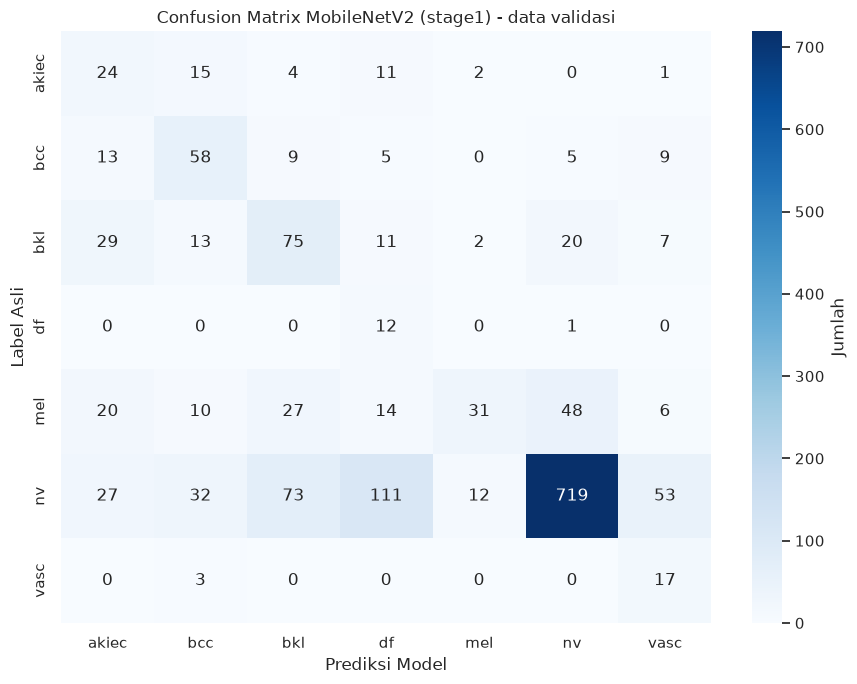

In [8]:
# Model yang akan dipakai untuk aplikasi: pilihan berbasis angka
if pilih_tahap2:
    model_final = model_mnv2
    final_results = res_s2
    final_stage = "stage2"
    y_pred_final = y_pred_s2
    y_proba_final = y_proba_s2
else:
    model_final = model_tahap1_final
    final_results = res_s1
    final_stage = "stage1"
    y_pred_final = y_pred_s1
    y_proba_final = y_proba_s1

E.print_report(final_results, f"MobileNetV2 ({final_stage}) - VALIDASI")

E.plot_confusion_matrix(
    y_val, y_pred_final,
    title=f"Confusion Matrix MobileNetV2 ({final_stage}) - data validasi",
    save_path=C.DOCS_ASSETS / "mnv2_03_confusion_matrix.png",
)


## Bagian 8: Analisis Error MobileNetV2

Sama seperti di notebook CNN, kita melihat contoh melanoma yang salah
diklasifikasi. Tapi kali ini kita juga membandingkan dengan apa yang
dilakukan model klasik, untuk melihat apakah deep learning memang
lebih baik.


Contoh prediksi salah untuk kelas 'mel': 125 dari 156


Contoh error disimpan: /mnt/m/GrenPlums Roses/Program32bit/Forestrypansy/ML2026_Kelas_3_Kelompok_1_LesiKulit/docs/assets/mnv2_04_error_melanoma.png


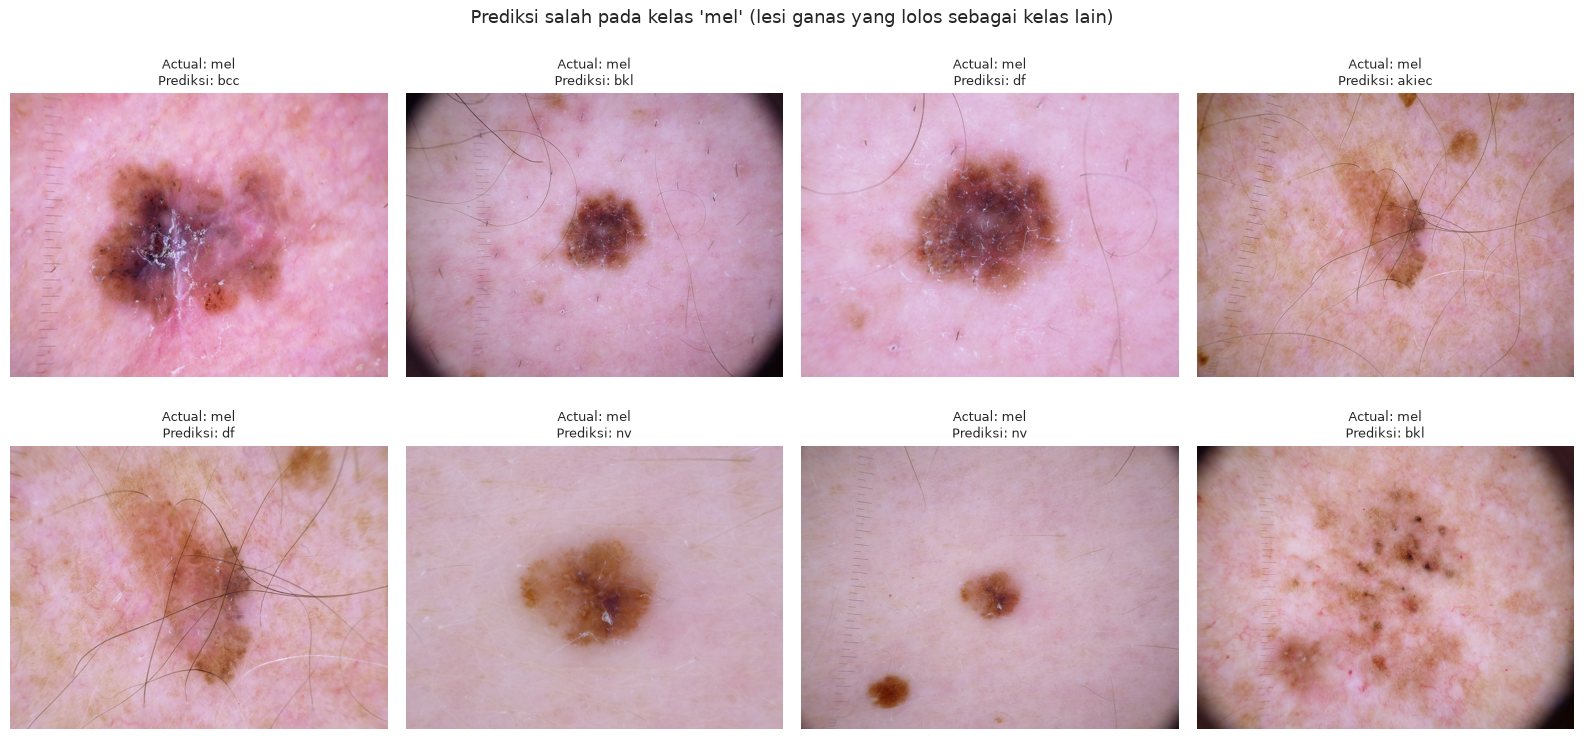

In [9]:
E.plot_error_analysis(
    y_val, y_pred_final,
    image_paths=df_val["image_path"].tolist(),
    class_names=C.CLASSES,
    n_examples=8,
    focus_class="mel",
    save_path=C.DOCS_ASSETS / "mnv2_04_error_melanoma.png",
)


## Bagian 9: Analisis Error - Perbandingan Visual Semua Model

Ini visualisasi yang sangat berguna untuk presentasi: satu gambar,
empat prediksi model. Kita bisa langsung melihat model mana yang paling
sering benar.


Model klasik dimuat (dari Notebook 04).


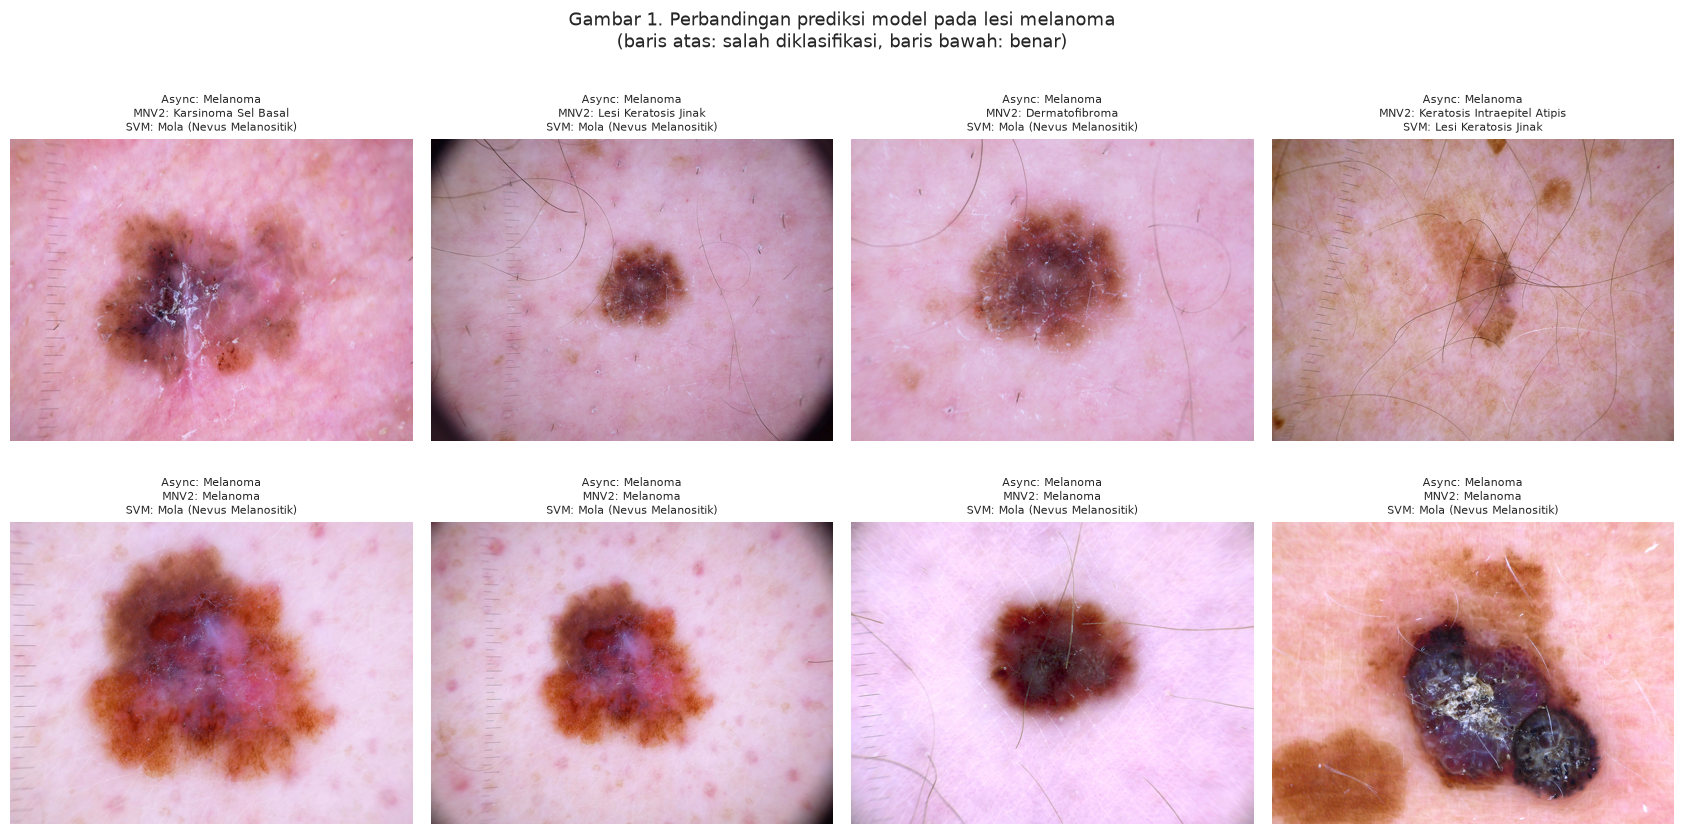

In [10]:
import joblib
from PIL import Image

# Muat model klasik dari Notebook 04 (kalau sudah ada)
svm_model = None
rf_model = None
svm_path = C.MODELS_DIR / "svm_hog.joblib"
rf_path = C.MODELS_DIR / "rf_hog.joblib"
if svm_path.exists() and rf_path.exists():
    svm_model = joblib.load(svm_path)
    rf_model = joblib.load(rf_path)
    print("Model klasik dimuat (dari Notebook 04).")

# Ambil beberapa gambar validation yang tricky: melanoma yang salah
# diprediksi oleh MobileNetV2
wrong_mel = np.where((y_val == C.CLASS_TO_IDX["mel"]) &
                      (y_pred_final != C.CLASS_TO_IDX["mel"]))[0][:4]
# Dan beberapa yang benar
right_mel = np.where((y_val == C.CLASS_TO_IDX["mel"]) &
                     (y_pred_final == C.CLASS_TO_IDX["mel"]))[0][:4]
indeks = list(wrong_mel) + list(right_mel)

if indeks:
    fig, axes = plt.subplots(2, 4, figsize=(17, 9))
    for i, idx in enumerate(indeks[:8]):
        row, col = i // 4, i % 4
        ax = axes[row][col]
        img = Image.open(df_val.iloc[idx]["image_path"]).convert("RGB")
        ax.imshow(img)

        judul = [f"Async: {C.DX_INDO[C.CLASSES[y_val[idx]]]}"]
        judul.append(f"MNV2: {C.DX_INDO[C.CLASSES[y_pred_final[idx]]]}")
        if svm_model is not None:
            from src import features as F
            img_small = img.resize((C.IMG_SIZE_CLASSIC, C.IMG_SIZE_CLASSIC),
                                   Image.BILINEAR)
            # PENTING: extract_features_single mengembalikan vektor 1D
            # (1812 angka), sedangkan model sklearn dilatih pada matriks
            # 2D (n_samples x n_features). Tanpa reshape, ColumnTransformer
            # akan salah menghitung jumlah kolom dan melempar
            # "X does not contain any features".
            feat = F.extract_features_single(img_small).reshape(1, -1)
            svm_pred = C.CLASSES[int(svm_model.predict(feat)[0])]
            judul.append(f"SVM: {C.DX_INDO[svm_pred]}")
        ax.set_title("\n".join(judul), fontsize=8)
        ax.axis("off")

    plt.suptitle("Gambar 1. Perbandingan prediksi model pada lesi melanoma\n"
                 "(baris atas: salah diklasifikasi, baris bawah: benar)",
                 fontsize=13, y=0.99)
    plt.tight_layout()
    plt.savefig(C.DOCS_ASSETS / "mnv2_05_perbandingan_model.png",
                bbox_inches="tight")
    plt.show()


**Interpretasi Bagian 9:**

Perbandingan ini sangat berguna untuk laporan, karena menunjukkan
**ke-coldan relatif** dari tiap pendekatan:

- **HOG-SVM/RF** menangkap bentuk dan warna dalam bentuk yang sangat
  sederhana (gradien + histogram). Kalau cirinya tidak terbaca
  secara utuh, model ini akan salah.
- **MobileNetV2** bisa belajar representasi yang jauh lebih abstrak
  (misal "pola asimetris + warna tidak merata" sebagai satu fitur),
  sehingga biasanya lebih robust.

**Tapi** MobileNetV2 juga punya kelemahan sendiri: ia bisa "terlalu
yakin" pada pola yang biasa, dan punya bias terhadap gaya foto
dermoskopi. Itu justru mendorong uji domain shift di Fase 7.


## Bagian 10: Menyimpan Model MobileNetV2

**Yang disimpan:**
1. `models/mobilenetv2_best.keras` - model final (tahap 1 atau 2)
2. `models/label_map.json` - pemetaan indeks -> nama kelas
3. `models/preprocess_config.json` - aturan preprocessing untuk aplikasi

**Penting untuk aplikasi:** config preprocessing memuat **ukuran gambar
(224) dan aturan normalisasi (rescaling_1_127.5_offset_-1)**, supaya
aplikasi web tidak bisa salah preprocessing. Kita menulis ini dari
`src/modeling.py`, bukan manual, sehingga mustahil tidak sinkron.


In [11]:
modeling.save_model(
    model_final,
    run_name="mobilenetv2_best",
    extra_config={
        "model_type": "mobilenetv2_transfer_learning",
        "stage_used": final_stage,
        "img_size": C.IMG_SIZE_MOBILENET,
        "normalization": "rescaling_1_127.5_offset_-1",
        "epochs_stage1": len(history_stage1.history["loss"]),
        "epochs_stage2": len(history_stage2.history["loss"]),
        "validation_f1_macro": final_results["f1_macro"],
        "validation_malignant_recall":
            final_results["binary"]["malignant_recall"],
        "total_params": model_final.count_params(),
    },
)


Model disimpan: /mnt/m/GrenPlums Roses/Program32bit/Forestrypansy/ML2026_Kelas_3_Kelompok_1_LesiKulit/models/mobilenetv2_best.keras (9.3 MB)
Label map disimpan: /mnt/m/GrenPlums Roses/Program32bit/Forestrypansy/ML2026_Kelas_3_Kelompok_1_LesiKulit/models/label_map.json
Config preprocessing disimpan: /mnt/m/GrenPlums Roses/Program32bit/Forestrypansy/ML2026_Kelas_3_Kelompok_1_LesiKulit/models/preprocess_config.json


PosixPath('/mnt/m/GrenPlums Roses/Program32bit/Forestrypansy/ML2026_Kelas_3_Kelompok_1_LesiKulit/models/mobilenetv2_best.keras')

## Bagian 11: Ringkasan dan Langkah Berikutnya

**Yang sudah dilakukan:**
- Transfer learning 2 tahap (classifier -> fine-tuning sebagian atas)
- BatchNormalization dikunci saat fine-tuning (dengan `assert` sebagai bukti)
- Augmentasi gaya-smartphone (blur via kompresi JPEG, brightness,
  contrast, hue, zoom) untuk_memberi kesiapan domain shift
- Perbandingan Tahap 1 vs Tahap 2, pemilihan berdasarkan angka
- Confusion matrix + analisis error + perbandingan visual antar model
- Model + config preprocessing disimpan

**Angka kunci:**
- Stage dipakai : {final_stage}
- F1 macro      : {final_results['f1_macro']:.4f}
- Recall ganas  : {final_results['binary']['malignant_recall']:.4f}
- Parameter     : {model_final.count_params():,}

**Langkah berikutnya (Fase 7):** Evaluasi Perbandingan di
`07_evaluasi_perbandingan.ipynb` - menguji keempat model pada test set
yang SAMA, membuat tabel perbandingan, menentukan threshold ganas dari
data validasi, dan memilih model terbaik untuk aplikasi.


In [12]:
summary_mnv2 = {
    "stage_used": final_stage,
    "f1_macro": final_results["f1_macro"],
    "accuracy": final_results["accuracy"],
    "malignant_recall": final_results["binary"]["malignant_recall"],
    "total_params": model_final.count_params(),
    "stage1": {
        "best_val_loss": best_val_loss_s1,
        "best_epoch": best_epoch_s1,
        "epochs": len(history_stage1.history["loss"]),
        "time_s": round(time_stage1, 1),
    },
    "stage2": {
        "best_val_loss": best_val_loss_s2,
        "best_epoch": best_epoch_s2,
        "epochs": len(history_stage2.history["loss"]),
        "time_s": round(time_stage2, 1),
    },
    # Metrik lengkap tiap tahap, supaya tabel perbandingan tahap 1 vs
    # tahap 2 di laporan bisa diambil dari file ini, bukan diketik manual.
    "stage1_result": res_s1,
    "stage2_result": res_s2,
    "perbandingan": {
        "f1_macro": {
            "stage1": res_s1["f1_macro"] if res_s1 else None,
            "stage2": res_s2["f1_macro"],
        },
        "accuracy": {
            "stage1": res_s1["accuracy"] if res_s1 else None,
            "stage2": res_s2["accuracy"],
        },
        "malignant_recall": {
            "stage1": (res_s1["binary"]["malignant_recall"]
                       if res_s1 else None),
            "stage2": res_s2["binary"]["malignant_recall"],
        },
        "fn_malignant": {
            "stage1": res_s1["binary"]["fn"] if res_s1 else None,
            "stage2": res_s2["binary"]["fn"],
        },
        "fp": {
            "stage1": res_s1["binary"]["fp"] if res_s1 else None,
            "stage2": res_s2["binary"]["fp"],
        },
    },
}
out = C.REPO_ROOT / "docs" / "logs" / "model_mobilenetv2_validasi.json"
out.parent.mkdir(parents=True, exist_ok=True)
with open(out, "w", encoding="utf-8") as f:
    json.dump(summary_mnv2, f, indent=2, ensure_ascii=False)
print(f"Ringkasan MobileNetV2 disimpan: {out}")
print("\nNotebook 06 selesai.")


Ringkasan MobileNetV2 disimpan: /mnt/m/GrenPlums Roses/Program32bit/Forestrypansy/ML2026_Kelas_3_Kelompok_1_LesiKulit/docs/logs/model_mobilenetv2_validasi.json

Notebook 06 selesai.
